# 04 - Entrenamiento, ajuste y selección de modelos

**Proyecto 2 - Pipeline de Machine Learning (Predict Future Sales)**

Brady Monroy (15003165) y Luis Rodolfo Rodriguez

En este notebook se hace el **torneo de modelos**, igual que en clase:
1. Se prueban **6 modelos** distintos (los vistos en clase): Ridge, Lasso, ElasticNet, Random Forest, Gradient
   Boosting y una red neuronal (MLP).
2. Cada modelo se prueba con **3 configuraciones** de hiperparámetros: **18 modelos en total** (la consigna pide al
   menos 15).
3. Se comparan con el **RMSE** en el set de validación y se elige el ganador.
4. El ganador se agrega como **paso final** del pipeline de preprocesamiento y se guarda como `.pkl`.

## Configuración

Igual que en clase, cada modelo se entrena dentro de un `Pipeline` que tiene primero la ingeniería de
características (`fe`) y después el modelo. Así los dos se ajustan juntos con los mismos datos y no hay fuga de
información.

In [1]:
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 80)
sns.set_style("whitegrid")

PROJ_ROOT = Path.cwd().parent
PROCESSED_DATA_DIR = PROJ_ROOT / "data" / "processed"
MODELS_DIR = PROJ_ROOT / "models"

# Para poder abrir el pipeline, primero se importa el Mapper
sys.path.append(str(PROJ_ROOT))
from src.features.preprocesadores import Mapper

RANDOM_STATE = 42

with open(PROJ_ROOT / "pipeline_config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

MODEL_FEATURES = config["MODEL_FEATURES"]
TARGET = config["TARGET"]

## Pipeline de ingeniería de características (del notebook 03)

Se carga `pipeline_fe.pkl` y se **clona** con `clone`, como en clase: se conserva la configuración de cada paso, pero
se borra lo aprendido (medianas, límites, lambdas, medias). Así cada modelo vuelve a ajustar el preprocesamiento con
sus propios datos de entrenamiento.

In [2]:
pipeline_fe = clone(joblib.load(MODELS_DIR / "pipeline_fe.pkl"))
pipeline_fe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('traducir_nombres', ...), ('imputar_mediana', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,mappings,"{'ciudad': {'Адыгея': 'Adigueya', 'Балашиха': 'Balashija', 'Волжский': 'Volzhski', 'Вологда': 'Vologda', ...}, 'grupo_categoria': {'PC': 'Audifonos de PC', 'Аксессуары': 'Accesorios', 'Билеты (Цифра)': 'Boletos digitales', 'Доставка товара': 'Envios', ...}}"
,unknown_value,'Otro'
,variables,['venta_tienda_lag_1']
,imputation_method,'median'
,imputation_method,'frequent'
,variables,"['ciudad', 'grupo_categoria']"
,fill_value,'Missing'


## Datos de entrenamiento y validación

La división es **en orden de tiempo**, como pide la consigna:
- **Entrenamiento:** meses 0 a 26 (el primer 80%).
- **Validación:** meses 27 a 33 (los últimos 7 meses, cerca del 20% final).

**Muestra para el torneo:** entrenar 18 modelos con todas las filas de entrenamiento tomaría muchas horas en una computadora
personal (algunos modelos, como Gradient Boosting, usan un solo núcleo). Por eso cada modelo se entrena con una
**muestra aleatoria de 200,000 filas** de los meses 0 a 26, y se evalúa con **todas** las filas de validación
(meses 27 a 33). Todos los modelos usan la misma muestra, así que la comparación es justa.

In [3]:
mensual = pd.read_parquet(PROCESSED_DATA_DIR / "ventas_mensuales.parquet")

es_train = (mensual["date_block_num"] >= config["PRIMER_MES_TRAIN"]) & (mensual["date_block_num"] <= config["ULTIMO_MES_TRAIN"])
es_valid = (mensual["date_block_num"] >= config["PRIMER_MES_VALID"]) & (mensual["date_block_num"] <= config["ULTIMO_MES_VALID"])

train = mensual[es_train]
valid = mensual[es_valid]

# Muestra aleatoria para el torneo
TAMANO_MUESTRA = 200_000
muestra = train.sample(n=TAMANO_MUESTRA, random_state=RANDOM_STATE)

X_muestra = muestra[MODEL_FEATURES]
y_muestra = muestra[TARGET]

X_valid = valid[MODEL_FEATURES]
y_valid = valid[TARGET]

print("Entrenamiento completo:", train.shape[0], "filas")
print("Muestra para el torneo:", X_muestra.shape[0], "filas")
print("Validación           :", X_valid.shape[0], "filas")
print()
print("Promedio de item_cnt_month en la muestra    :", round(y_muestra.mean(), 4))
print("Promedio de item_cnt_month en entrenamiento:", round(train[TARGET].mean(), 4))

Entrenamiento completo: 9299486 filas
Muestra para el torneo: 200000 filas
Validación           : 1614364 filas

Promedio de item_cnt_month en la muestra    : 0.3049
Promedio de item_cnt_month en entrenamiento: 0.3046


## Métrica: RMSE

El **RMSE** (raíz del error cuadrático medio) mide, en unidades vendidas, qué tan lejos están las predicciones de los
valores reales. Mientras más bajo, mejor. Es la métrica de la competencia.

Como la variable objetivo está recortada a [0, 20], las predicciones también se recortan a ese rango antes de calcular
el RMSE (un modelo lineal podría predecir valores negativos, que no tienen sentido).

**Puntos de referencia:** para saber si un modelo es bueno, se compara contra dos predicciones muy simples:
- Predecir siempre **0**.
- Predecir que el mes vendrá igual que el mes anterior (**`lag_1`**).

In [4]:
def rmse_recortado(y_real, y_predicho):
    # Recortar las predicciones al rango [0, 20] y calcular el RMSE
    y_predicho = np.clip(y_predicho, 0, 20)
    return root_mean_squared_error(y_real, y_predicho)


rmse_cero = rmse_recortado(y_valid, np.zeros(len(y_valid)))
rmse_lag1 = rmse_recortado(y_valid, X_valid["lag_1"])

print("RMSE en validación prediciendo siempre 0 :", round(rmse_cero, 4))
print("RMSE en validación prediciendo con lag_1 :", round(rmse_lag1, 4))

RMSE en validación prediciendo siempre 0 : 1.1159
RMSE en validación prediciendo con lag_1 : 1.0373


## Modelos y configuraciones

Los mismos tipos de modelo vistos en clase, con 3 configuraciones cada uno:

| Modelo | Tipo | Hiperparámetro que cambia |
|---|---|---|
| Ridge | Regresión lineal con penalización L2 | `alpha` |
| Lasso | Regresión lineal con penalización L1 | `alpha` |
| ElasticNet | Regresión lineal L1 + L2 | `alpha` |
| Random Forest | Ensamble de árboles (bagging) | `max_depth` |
| Gradient Boosting | Ensamble de árboles (boosting) | `max_depth`, `n_estimators`, `learning_rate` |
| MLP | Red neuronal | `hidden_layer_sizes` |

Los valores de los árboles son más pequeños que en clase (por ejemplo, 100 árboles en lugar de 300) para que el
entrenamiento termine en un tiempo razonable con 200,000 filas.

In [5]:
# Cada configuración: (descripción, modelo)
modelos = {
    "Ridge": [
        ("alpha=0.1", Ridge(alpha=0.1)),
        ("alpha=1", Ridge(alpha=1)),
        ("alpha=10", Ridge(alpha=10)),
    ],
    "Lasso": [
        ("alpha=0.0001", Lasso(alpha=0.0001, max_iter=5000)),
        ("alpha=0.001", Lasso(alpha=0.001, max_iter=5000)),
        ("alpha=0.01", Lasso(alpha=0.01, max_iter=5000)),
    ],
    "ElasticNet": [
        ("alpha=0.0001, l1_ratio=0.5", ElasticNet(alpha=0.0001, l1_ratio=0.5, max_iter=5000)),
        ("alpha=0.001, l1_ratio=0.5", ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=5000)),
        ("alpha=0.01, l1_ratio=0.5", ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=5000)),
    ],
    "Random Forest": [
        ("max_depth=8", RandomForestRegressor(n_estimators=100, max_depth=8, min_samples_leaf=5,
                                              n_jobs=-1, random_state=RANDOM_STATE)),
        ("max_depth=12", RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=5,
                                               n_jobs=-1, random_state=RANDOM_STATE)),
        ("max_depth=16", RandomForestRegressor(n_estimators=100, max_depth=16, min_samples_leaf=5,
                                               n_jobs=-1, random_state=RANDOM_STATE)),
    ],
    "Gradient Boosting": [
        ("max_depth=3, n=100, lr=0.1", GradientBoostingRegressor(max_depth=3, n_estimators=100, learning_rate=0.1,
                                                                 subsample=0.8, random_state=RANDOM_STATE)),
        ("max_depth=5, n=100, lr=0.1", GradientBoostingRegressor(max_depth=5, n_estimators=100, learning_rate=0.1,
                                                                 subsample=0.8, random_state=RANDOM_STATE)),
        ("max_depth=5, n=200, lr=0.05", GradientBoostingRegressor(max_depth=5, n_estimators=200, learning_rate=0.05,
                                                                  subsample=0.8, random_state=RANDOM_STATE)),
    ],
    "MLP": [
        ("capas=(32,)", MLPRegressor(hidden_layer_sizes=(32,), early_stopping=True, max_iter=200,
                                     random_state=RANDOM_STATE)),
        ("capas=(64,)", MLPRegressor(hidden_layer_sizes=(64,), early_stopping=True, max_iter=200,
                                     random_state=RANDOM_STATE)),
        ("capas=(64, 32)", MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=200,
                                        random_state=RANDOM_STATE)),
    ],
}

total = sum(len(lista) for lista in modelos.values())
print("Modelos a entrenar:", total)

Modelos a entrenar: 18


## Torneo: entrenar y evaluar los 18 modelos

Para cada configuración:
1. Se arma el pipeline `fe` + `modelo`.
2. Se entrena con la muestra de los meses 0 a 26.
3. Se calcula el RMSE en la muestra de entrenamiento y en validación.

Si el RMSE de entrenamiento es mucho menor que el de validación, el modelo está **sobreajustado** (memorizó los
datos). Esta celda tarda varios minutos.

In [6]:
resultados = []

for nombre_modelo, configuraciones in modelos.items():
    for descripcion, estimador in configuraciones:
        inicio = time.time()

        # Pipeline: ingeniería de características + modelo
        pipe = Pipeline([("fe", clone(pipeline_fe)), ("modelo", clone(estimador))])
        pipe.fit(X_muestra, y_muestra)

        rmse_train = rmse_recortado(y_muestra, pipe.predict(X_muestra))
        rmse_valid = rmse_recortado(y_valid, pipe.predict(X_valid))
        minutos = (time.time() - inicio) / 60

        resultados.append({
            "modelo": nombre_modelo,
            "configuracion": descripcion,
            "rmse_train": rmse_train,
            "rmse_valid": rmse_valid,
            "minutos": minutos,
            "estimador": estimador,
        })
        print(nombre_modelo, "|", descripcion, "| RMSE valid =", round(rmse_valid, 4),
              "| minutos =", round(minutos, 1))

Ridge | alpha=0.1 | RMSE valid = 1.0165 | minutos = 0.2


Ridge | alpha=1 | RMSE valid = 1.0159 | minutos = 0.2


Ridge | alpha=10 | RMSE valid = 1.0125 | minutos = 0.2


Lasso | alpha=0.0001 | RMSE valid = 1.0131 | minutos = 0.3


Lasso | alpha=0.001 | RMSE valid = 1.0128 | minutos = 0.3


Lasso | alpha=0.01 | RMSE valid = 1.014 | minutos = 0.2


... (8 outputs left out)

Gradient Boosting | max_depth=5, n=200, lr=0.05 | RMSE valid = 0.8527 | minutos = 2.8


MLP | capas=(32,) | RMSE valid = 0.9257 | minutos = 0.9


MLP | capas=(64,) | RMSE valid = 0.9222 | minutos = 0.9


MLP | capas=(64, 32) | RMSE valid = 0.9251 | minutos = 0.6


## Tabla del torneo

In [7]:
tabla = pd.DataFrame(resultados).drop(columns="estimador")
tabla = tabla.sort_values("rmse_valid").reset_index(drop=True)
tabla.index = tabla.index + 1          # posición en el torneo, empezando en 1
tabla.round(4)

,modelo,configuracion,rmse_train,rmse_valid,minutos
1,Gradient Boosting,"max_depth=5, n=100, lr=0.1",0.8871,0.8526,1.1887
2,Gradient Boosting,"max_depth=5, n=200, lr=0.05",0.8866,0.8527,2.8483
3,Gradient Boosting,"max_depth=3, n=100, lr=0.1",0.9467,0.8561,0.9276
4,Random Forest,max_depth=12,0.8488,0.8580,1.2130
5,Random Forest,max_depth=8,0.9143,0.8581,0.8952
6,Random Forest,max_depth=16,0.8107,0.8609,1.5709
7,MLP,"capas=(64,)",1.0188,0.9222,0.8732
8,MLP,"capas=(64, 32)",1.0064,0.9251,0.6387
9,MLP,"capas=(32,)",1.0200,0.9257,0.9091
10,ElasticNet,"alpha=0.0001, l1_ratio=0.5",1.1616,1.0114,0.3918


In [8]:
# Mejor configuración de cada modelo
mejor_por_modelo = tabla.loc[tabla.groupby("modelo")["rmse_valid"].idxmin()].sort_values("rmse_valid")
mejor_por_modelo.round(4)

,modelo,configuracion,rmse_train,rmse_valid,minutos
1,Gradient Boosting,"max_depth=5, n=100, lr=0.1",0.8871,0.8526,1.1887
4,Random Forest,max_depth=12,0.8488,0.8580,1.2130
7,MLP,"capas=(64,)",1.0188,0.9222,0.8732
10,ElasticNet,"alpha=0.0001, l1_ratio=0.5",1.1616,1.0114,0.3918
12,Ridge,alpha=10,1.1615,1.0125,0.2318
13,Lasso,alpha=0.001,1.1648,1.0128,0.2571


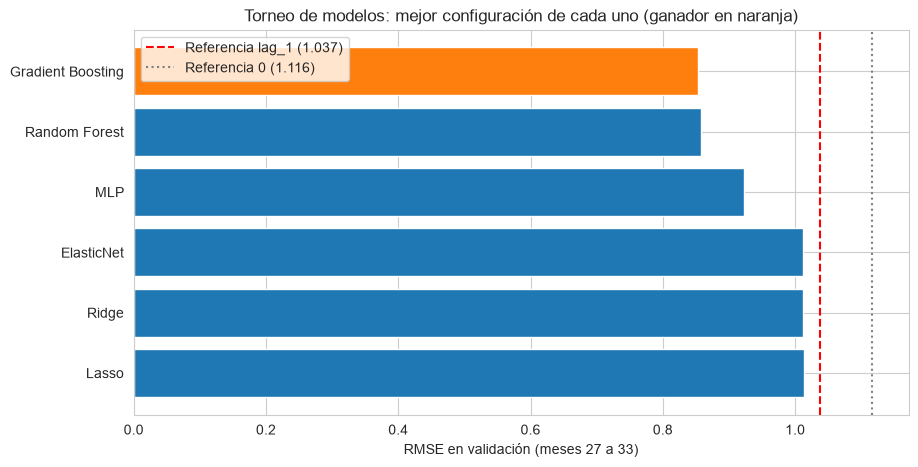

In [9]:
# Gráfica: mejor RMSE de validación de cada modelo, con las referencias
colores = ["tab:orange" if i == 0 else "tab:blue" for i in range(len(mejor_por_modelo))]

plt.figure(figsize=(10, 5))
plt.barh(mejor_por_modelo["modelo"], mejor_por_modelo["rmse_valid"], color=colores)
plt.axvline(rmse_lag1, color="red", linestyle="--", label="Referencia lag_1 (" + str(round(rmse_lag1, 3)) + ")")
plt.axvline(rmse_cero, color="gray", linestyle=":", label="Referencia 0 (" + str(round(rmse_cero, 3)) + ")")
plt.gca().invert_yaxis()
plt.xlabel("RMSE en validación (meses 27 a 33)")
plt.title("Torneo de modelos: mejor configuración de cada uno (ganador en naranja)")
plt.legend()
plt.show()

**Interpretación del torneo:**

| Grupo | Mejor RMSE en validación | Comparación con la referencia `lag_1` (1.0373) |
|---|---|---|
| Gradient Boosting | **0.8526** | 17.8% mejor |
| Random Forest | 0.8580 | 17.3% mejor |
| MLP | 0.9222 | 11.1% mejor |
| ElasticNet | 1.0114 | 2.5% mejor |
| Ridge | 1.0125 | 2.4% mejor |
| Lasso | 1.0128 | 2.4% mejor |

- **Referencias:** predecir siempre 0 da un RMSE de **1.1159** y repetir el mes anterior (`lag_1`) da **1.0373**.
  Los 18 modelos son mejores que predecir 0, pero los modelos lineales apenas mejoran a `lag_1`.
- **Los modelos de árboles ganan con claridad.** Las 6 configuraciones de Gradient Boosting y Random Forest ocupan
  los primeros 6 lugares, todas entre 0.8526 y 0.8609. Las dos mejores configuraciones de Gradient Boosting quedan
  casi empatadas (0.8526 y 0.8527), y el mejor Random Forest queda a solo **0.0054** del ganador.
- **¿Por qué ganan los árboles?** La gran mayoría de los valores son 0 y la relación entre las variables y las ventas
  no es una línea recta. Por ejemplo, vender 1 o 20 unidades el mes pasado no cambia la predicción en la misma
  proporción. Los árboles captan esos cambios y las combinaciones entre variables; los modelos lineales no.
- **Sobreajuste:** en Random Forest, mientras más profundo el árbol, menor el error de entrenamiento (0.9143 →
  0.8488 → 0.8107), pero el de validación casi no mejora y luego empeora (0.8581 → 0.8580 → 0.8609). El árbol más
  profundo memoriza la muestra. Por eso conviene una profundidad moderada.
- **Modelos lineales:** su RMSE de entrenamiento (cerca de 1.16) es mayor que el de validación (cerca de 1.01). No es
  un error: los meses de validación tienen menos ventas en promedio (tendencia a la baja vista en el EDA), así que los
  errores son más pequeños.
- **Tiempo:** el modelo más lento fue Gradient Boosting con 200 árboles (2.8 minutos); los lineales tardaron menos de
  medio minuto.

## Modelo ganador

Se elige automáticamente la configuración con **menor RMSE en validación**.

In [10]:
# Recorrer los resultados y quedarse con el de menor RMSE de validación
ganador = resultados[0]
for resultado in resultados:
    if resultado["rmse_valid"] < ganador["rmse_valid"]:
        ganador = resultado

print("Modelo ganador :", ganador["modelo"])
print("Configuración  :", ganador["configuracion"])
print("RMSE validación:", round(ganador["rmse_valid"], 4))

Modelo ganador : Gradient Boosting
Configuración  : max_depth=5, n=100, lr=0.1
RMSE validación: 0.8526


## Pipeline completo: preprocesamiento + modelo ganador

Igual que en clase, el ganador se **reentrena con entrenamiento + validación** (meses 0 a 33), porque así aprende
también de los meses más recientes, que son los más parecidos a noviembre de 2015.

Por el tiempo de entrenamiento se usa una muestra aleatoria de **1,000,000 de filas** de los meses 0 a 33 (cinco
veces más que en el torneo).

In [11]:
TAMANO_FINAL = 1_000_000

es_final = (mensual["date_block_num"] >= config["PRIMER_MES_TRAIN"]) & (mensual["date_block_num"] <= config["ULTIMO_MES_VALID"])
datos_final = mensual[es_final].sample(n=TAMANO_FINAL, random_state=RANDOM_STATE)

pipeline_completo = Pipeline([
    ("fe", clone(pipeline_fe)),
    ("modelo", clone(ganador["estimador"])),
])

inicio = time.time()
pipeline_completo.fit(datos_final[MODEL_FEATURES], datos_final[TARGET])
print("Entrenado en", round((time.time() - inicio) / 60, 1), "minutos")
pipeline_completo

Entrenado en 6.6 minutos


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('fe', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('traducir_nombres', ...), ('imputar_mediana', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,mappings,"{'ciudad': {'Адыгея': 'Adigueya', 'Балашиха': 'Balashija', 'Волжский': 'Volzhski', 'Вологда': 'Vologda', ...}, 'grupo_categoria': {'PC': 'Audifonos de PC', 'Аксессуары': 'Accesorios', 'Билеты (Цифра)': 'Boletos digitales', 'Доставка товара':

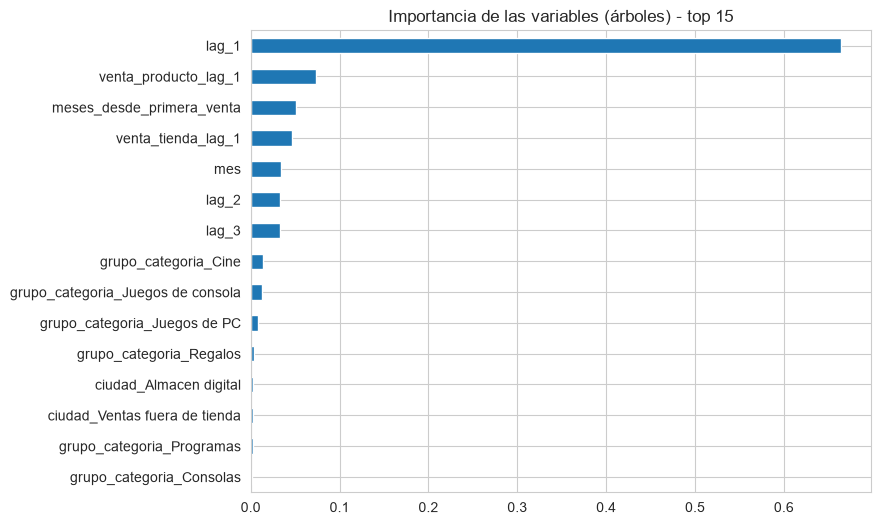

lag_1                                0.6644
venta_producto_lag_1                 0.0730
meses_desde_primera_venta            0.0511
venta_tienda_lag_1                   0.0460
mes                                  0.0346
lag_2                                0.0329
lag_3                                0.0328
grupo_categoria_Cine                 0.0134
grupo_categoria_Juegos de consola    0.0125
grupo_categoria_Juegos de PC         0.0085
grupo_categoria_Regalos              0.0040
ciudad_Almacen digital               0.0030
ciudad_Ventas fuera de tienda        0.0025
grupo_categoria_Programas            0.0020
grupo_categoria_Consolas             0.0020
dtype: float64


In [12]:
# Variables más importantes para el modelo ganador
modelo_final = pipeline_completo.named_steps["modelo"]
nombres_columnas = pipeline_completo.named_steps["fe"].transform(X_valid.head()).columns

if hasattr(modelo_final, "feature_importances_"):
    importancia = pd.Series(modelo_final.feature_importances_, index=nombres_columnas)
    titulo = "Importancia de las variables (árboles)"
elif hasattr(modelo_final, "coef_"):
    importancia = pd.Series(np.abs(modelo_final.coef_), index=nombres_columnas)
    titulo = "Tamaño de los coeficientes (modelo lineal)"
else:
    importancia = None
    print("Este modelo no da importancia de variables directamente.")

if importancia is not None:
    top15 = importancia.sort_values(ascending=False).head(15)
    top15.sort_values().plot(kind="barh", figsize=(8, 6))
    plt.title(titulo + " - top 15")
    plt.show()
    print(top15.round(4))

**Interpretación de la importancia de variables:**

- **`lag_1` es por mucho la variable más importante (0.664).** Coincide con el EDA (rezago 1 en ACF/PACF) y con la
  correlación del notebook 02.
- Las siguientes son variables **exógenas del producto y de la tienda**: `venta_producto_lag_1` (0.073),
  `meses_desde_primera_venta` (0.051) y `venta_tienda_lag_1` (0.046). Junto con las banderas de grupo y ciudad, las
  variables de tienda y producto suman **0.218** de importancia dentro del top 15. El modelo sí usa la información de
  tienda y producto, como pide la consigna.
- `mes` (0.035) ayuda a captar la estacionalidad.
- Entre las banderas, las más útiles son los grupos **Cine**, **Juegos de consola** y **Juegos de PC**, y las
  "ciudades" **Almacén digital** y **Ventas fuera de tienda**, que en el EDA se comportaban distinto a las tiendas
  normales.

## Guardar el pipeline completo

Se guarda en `models/pipeline_completo.pkl`. Este archivo contiene todo lo necesario para predecir: los seis pasos
de ingeniería de características y el modelo ganador. Es el que se usa en el notebook 05.

In [13]:
ruta_completo = MODELS_DIR / "pipeline_completo.pkl"
joblib.dump(pipeline_completo, ruta_completo)

# Comprobar que el archivo se puede cargar y predice igual
pipeline_cargado = joblib.load(ruta_completo)
prueba = X_valid.head(1000)
assert np.allclose(pipeline_cargado.predict(prueba), pipeline_completo.predict(prueba))

print("Pipeline completo guardado en:", ruta_completo)
print("Tamaño del archivo:", round(ruta_completo.stat().st_size / 1024**2, 1), "MB")

Pipeline completo guardado en: C:\Users\brady\OneDrive - Universidad Galileo\Documentos\PRODUCT DEVELOPMENT\Proyecto-1\models\pipeline_completo.pkl


Tamaño del archivo: 0.5 MB


**Resultado del notebook 04:**

- **Modelo ganador:** Gradient Boosting con `max_depth=5`, 100 árboles y `learning_rate=0.1`, con un RMSE de
  validación de **0.8526**.
- El ganador se reentrenó con **1,000,000 de filas** de los meses 0 a 33 (entrenamiento + validación) en
  6.6 minutos. Como ya incluye los meses de validación, este modelo final ya no se puede evaluar con ellos. Su
  desempeño esperado es el RMSE del torneo.
- Se generó **`models/pipeline_completo.pkl`** (0.5 MB), con los seis pasos de ingeniería de características y el
  modelo ganador como paso final.